In [1]:
import pandas as pd

#loading dataset
df = pd.read_csv("Mall_Customers.csv")

print(df.head())


   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [2]:
 #data cleaning
print(df.isnull().sum())

df = df.drop("CustomerID", axis=1)

df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


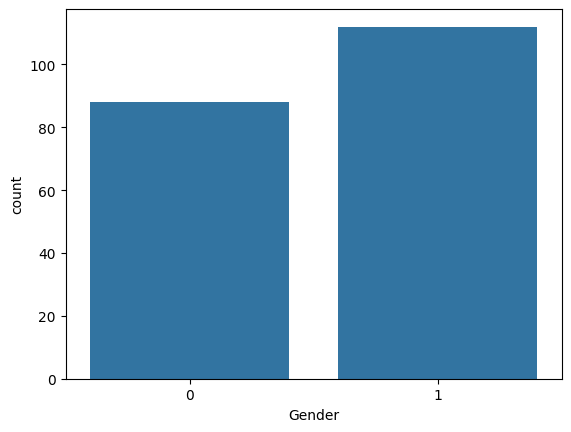

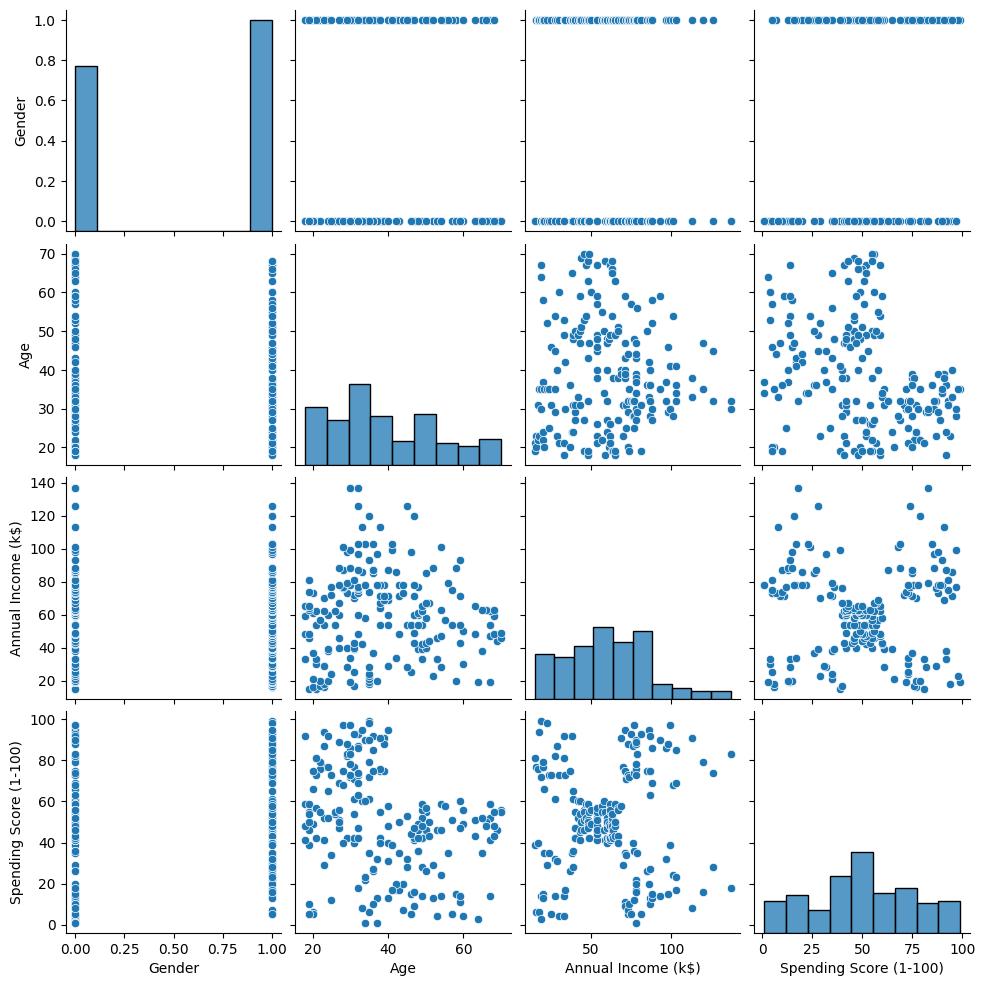

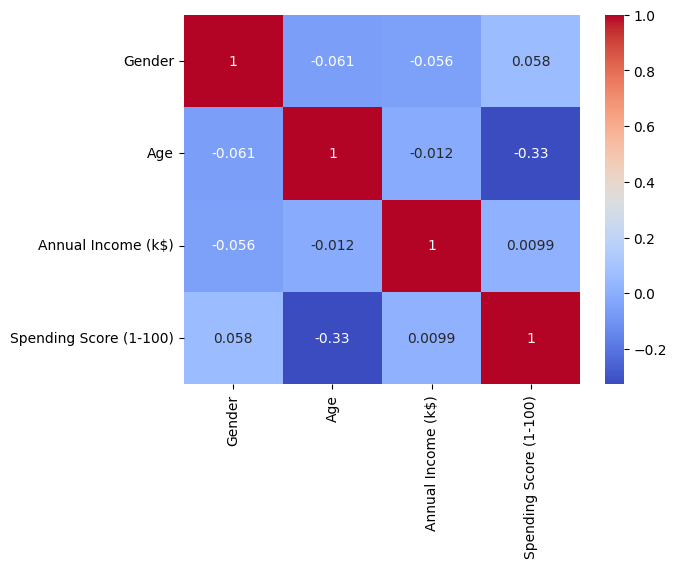

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

# Gender-wise count plot
sns.countplot(x='Gender', data=df)
plt.show()

# Pairplot for basic relations
sns.pairplot(df)
plt.show()

# Heatmap to see correlation
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()


In [11]:
from sklearn.preprocessing import StandardScaler

# Features select karo
X = df[['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

# Scale karo
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The defa

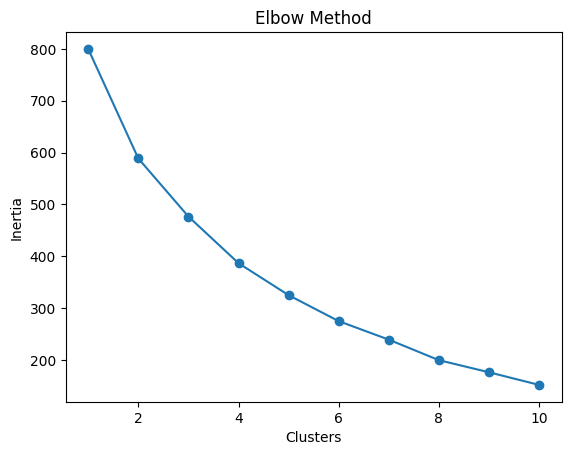

In [12]:
from sklearn.cluster import KMeans

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Clusters')
plt.ylabel('Inertia')
plt.show()


In [13]:
# For example, let’s choose 5 clusters
kmeans = KMeans(n_clusters=5, random_state=0)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print(df.head())


   Gender  Age  Annual Income (k$)  Spending Score (1-100)  Cluster      PCA1  \
0       0   19                  15                      39        1 -0.406383   
1       0   21                  15                      81        1 -1.427673   
2       1   20                  16                       6        4  0.050761   
3       1   23                  16                      77        2 -1.694513   
4       1   31                  17                      40        4 -0.313108   

       PCA2  
0 -0.520714  
1 -0.367310  
2 -1.894068  
3 -1.631908  
4 -1.810483  


C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


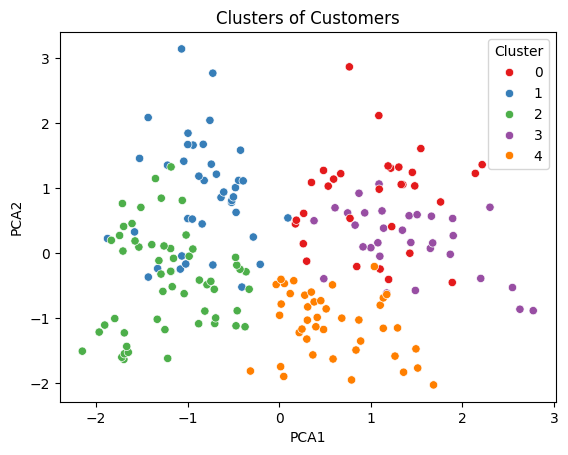

In [14]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
reduced = pca.fit_transform(X_scaled)

df['PCA1'] = reduced[:, 0]
df['PCA2'] = reduced[:, 1]

sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', data=df, palette='Set1')
plt.title("Clusters of Customers")
plt.show()


In [15]:
 
for i in range(5):
    print(f"Cluster {i} Summary:")
    print(df[df['Cluster'] == i].mean())
    print('---------------------------')


Cluster 0 Summary:
Gender                     0.451613
Age                       40.419355
Annual Income (k$)        90.000000
Spending Score (1-100)    15.741935
Cluster                    0.000000
PCA1                       1.040706
PCA2                       0.847056
dtype: float64
---------------------------
Cluster 1 Summary:
Gender                     0.000000
Age                       28.250000
Annual Income (k$)        62.000000
Spending Score (1-100)    71.675000
Cluster                    1.000000
PCA1                      -0.831991
PCA2                       0.914209
dtype: float64
---------------------------
Cluster 2 Summary:
Gender                     1.000000
Age                       28.392857
Annual Income (k$)        60.428571
Spending Score (1-100)    68.178571
Cluster                    2.000000
PCA1                      -1.203347
PCA2                      -0.409660
dtype: float64
---------------------------
Cluster 3 Summary:
Gender                     0.000000
Age

C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The defa

Silhouette Score for k=2: 0.252
Silhouette Score for k=3: 0.260
Silhouette Score for k=4: 0.298
Silhouette Score for k=5: 0.304


C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The defa

Silhouette Score for k=6: 0.331
Silhouette Score for k=7: 0.357
Silhouette Score for k=8: 0.388
Silhouette Score for k=9: 0.403
Silhouette Score for k=10: 0.421


C:\Users\hp pc\AppData\Roaming\Python\Python311\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


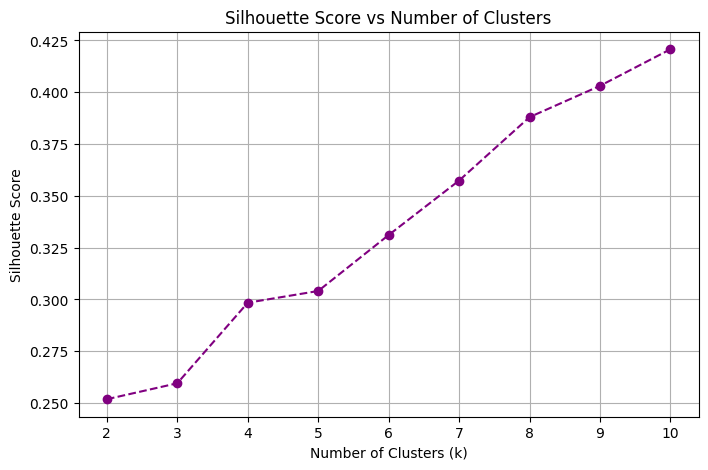

In [ ]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)  
    score = silhouette_score(X_scaled, labels) 
    silhouette_scores.append(score)
    print(f"Silhouette Score for k={k}: {score:.3f}")

# Plot
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker='o', linestyle='--', color='purple')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs Number of Clusters")
plt.grid(True)
plt.show()
